# Actividad 2. Dataset y notebook baseline

**Nombre:** Gerardo González Martínez  
**Matrícula:** A01840096  
**Curso:** TC5061.10, Operaciones de aprendizaje automático (MLOps)  
**Programa:** Maestría en Inteligencia Artificial Aplicada  
**Fecha:** 4 de octubre de 2026  
**Repositorio:** https://github.com/gerardoglezmart/mna-tc5061-actividad2-notebook-baseline

---

Flujo básico de un proyecto de machine learning sobre el dataset Wine Quality del UCI
Machine Learning Repository, con el experimento registrado en MLflow Tracking.


## 1. Carga y descripción del dataset

Wine Quality (vino tinto), el mismo que se revisó en clase. Son mediciones fisicoquímicas de
vinos portugueses con una calificación de calidad asignada por catadores. El dataset es de Cortez et al. (2009) y la copia local viene
de [archive.ics.uci.edu](https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv).


In [1]:
import pathlib

import matplotlib.pyplot as plt
import mlflow
import pandas as pd

df = pd.read_csv("../data/raw/winequality-red.csv", sep=";")
print("Registros y variables:", df.shape)

Registros y variables: (1599, 12)


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [3]:
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


### Significado de las variables

Las 11 primeras son mediciones de laboratorio y `quality` es la variable objetivo.

| Variable | Significado | Tipo |
|---|---|---|
| fixed acidity | Acidez fija, ácido tartárico en g/dm3 | float |
| volatile acidity | Acidez volátil, ácido acético en g/dm3 | float |
| citric acid | Ácido cítrico en g/dm3 | float |
| residual sugar | Azúcar que queda tras la fermentación en g/dm3 | float |
| chlorides | Cloruros, sal en g/dm3 | float |
| free sulfur dioxide | Dióxido de azufre libre en mg/dm3 | float |
| total sulfur dioxide | Dióxido de azufre total en mg/dm3 | float |
| density | Densidad en g/cm3 | float |
| pH | Acidez en escala de pH | float |
| sulphates | Sulfatos en g/dm3 | float |
| alcohol | Grado alcohólico en porcentaje de volumen | float |
| quality | Calidad asignada por catadores, escala de 0 a 10 | int |


## 2. Análisis exploratorio (EDA)


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.319637,1.741096,4.60000,7.1000,7.90000,9.200000,15.90000
volatile acidity,1599.0,0.527821,0.179060,0.12000,0.3900,0.52000,0.640000,1.58000
citric acid,1599.0,0.270976,0.194801,0.00000,0.0900,0.26000,0.420000,1.00000
residual sugar,1599.0,2.538806,1.409928,0.90000,1.9000,2.20000,2.600000,15.50000
chlorides,1599.0,0.087467,0.047065,0.01200,0.0700,0.07900,0.090000,0.61100
free sulfur dioxide,1599.0,15.874922,10.460157,1.00000,7.0000,14.00000,21.000000,72.00000
total sulfur dioxide,1599.0,46.467792,32.895324,6.00000,22.0000,38.00000,62.000000,289.00000
density,1599.0,0.996747,0.001887,0.99007,0.9956,0.99675,0.997835,1.00369
pH,1599.0,3.311113,0.154386,2.74000,3.2100,3.31000,3.400000,4.01000
sulphates,1599.0,0.658149,0.169507,0.33000,0.5500,0.62000,0.730000,2.00000


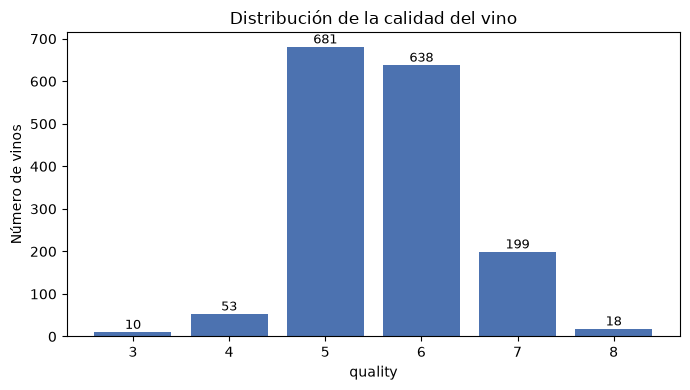

Calidad 7 u 8: 13.6 % de los vinos


In [5]:
conteo = df["quality"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(conteo.index.astype(str), conteo.values, color="#4c72b0")
ax.set_title("Distribución de la calidad del vino")
ax.set_xlabel("quality")
ax.set_ylabel("Número de vinos")
for x, y in zip(conteo.index.astype(str), conteo.values):
    ax.text(x, y + 8, str(y), ha="center", fontsize=9)
plt.tight_layout()
plt.show()

print("Calidad 7 u 8:", round(100 * (df["quality"] >= 7).mean(), 1), "% de los vinos")

Las calidades 5 y 6 concentran el 82 % de los vinos y solo el 13.6 % de los datos originales llega a 7 u 8. Ese
desbalance decide cómo hay que evaluar el modelo más adelante.


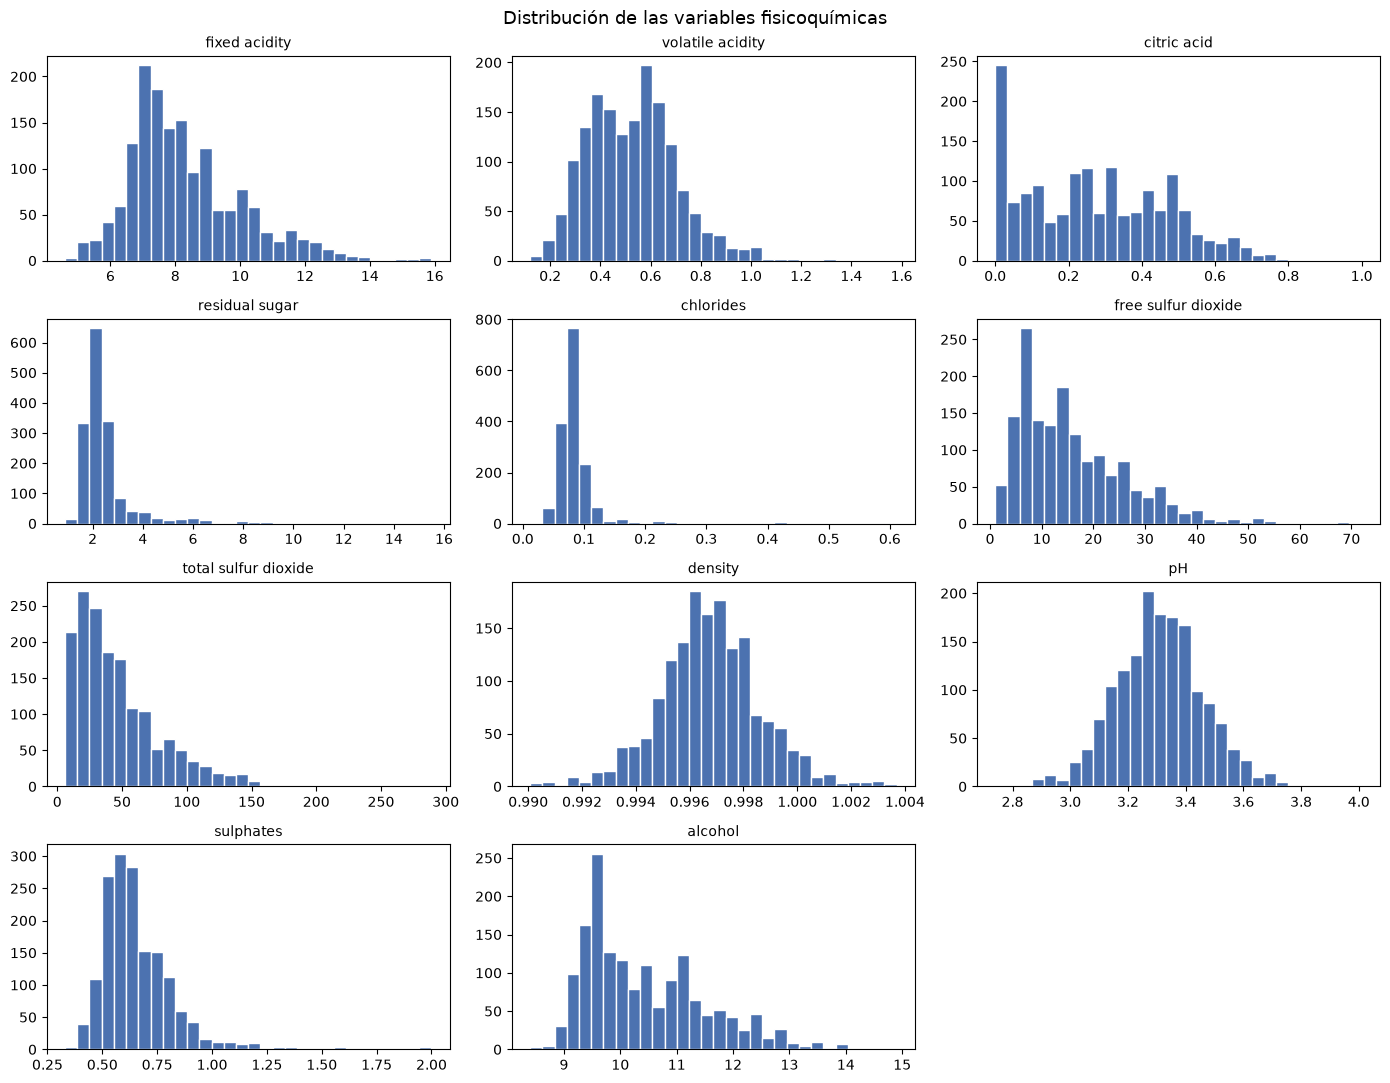

In [6]:
variables = [col for col in df.columns if col != "quality"]

fig, axes = plt.subplots(4, 3, figsize=(14, 11))
for ax, col in zip(axes.flat, variables):
    ax.hist(df[col], bins=30, color="#4c72b0", edgecolor="white")
    ax.set_title(col, fontsize=10)
axes.flat[-1].axis("off")
fig.suptitle("Distribución de las variables fisicoquímicas", fontsize=13)
plt.tight_layout()
plt.show()

`residual sugar`, `chlorides`, `sulphates` y los dos tipos de dióxido de azufre tienen colas
largas a la derecha. Además, las escalas van de décimas a centenas. Como la regresión logística
penaliza el tamaño de los coeficientes, conviene estandarizar las variables para que la
regularización las trate por igual. El escalado no corrige la asimetría, solo iguala escalas.


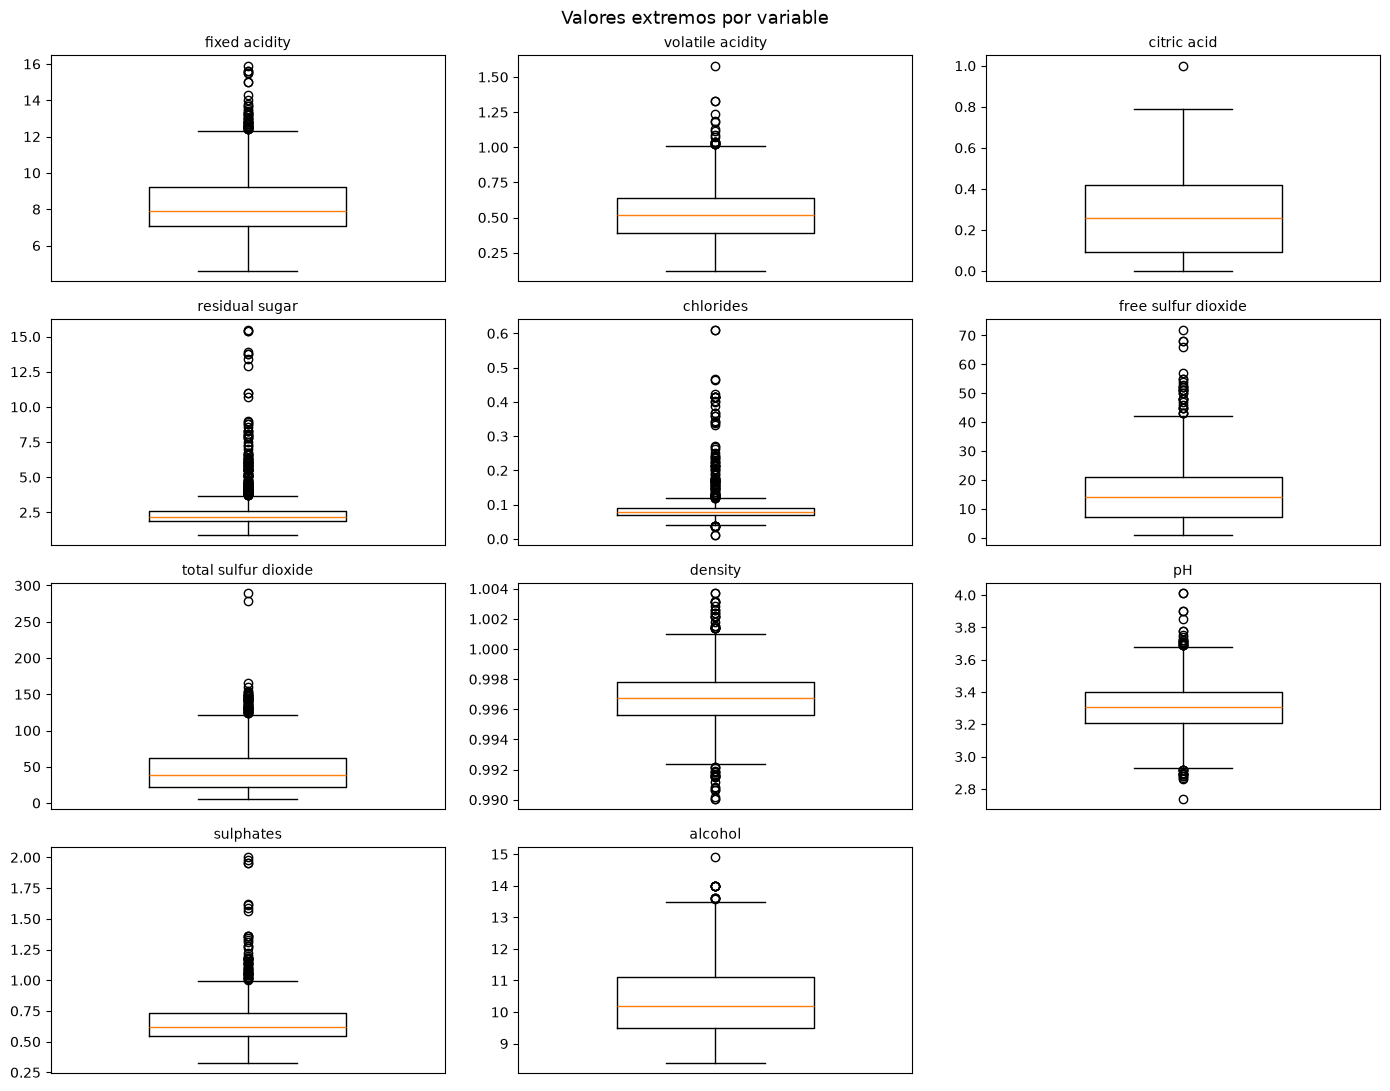

In [7]:
fig, axes = plt.subplots(4, 3, figsize=(14, 11))
for ax, col in zip(axes.flat, variables):
    ax.boxplot(df[col], orientation="vertical", widths=0.5)
    ax.set_title(col, fontsize=10)
    ax.set_xticks([])
axes.flat[-1].axis("off")
fig.suptitle("Valores extremos por variable", fontsize=13)
plt.tight_layout()
plt.show()

Todas las variables tienen puntos fuera de los bigotes. Queda pendiente decidir si son errores
de medición o vinos realmente atípicos, cosa que se resuelve en la limpieza.


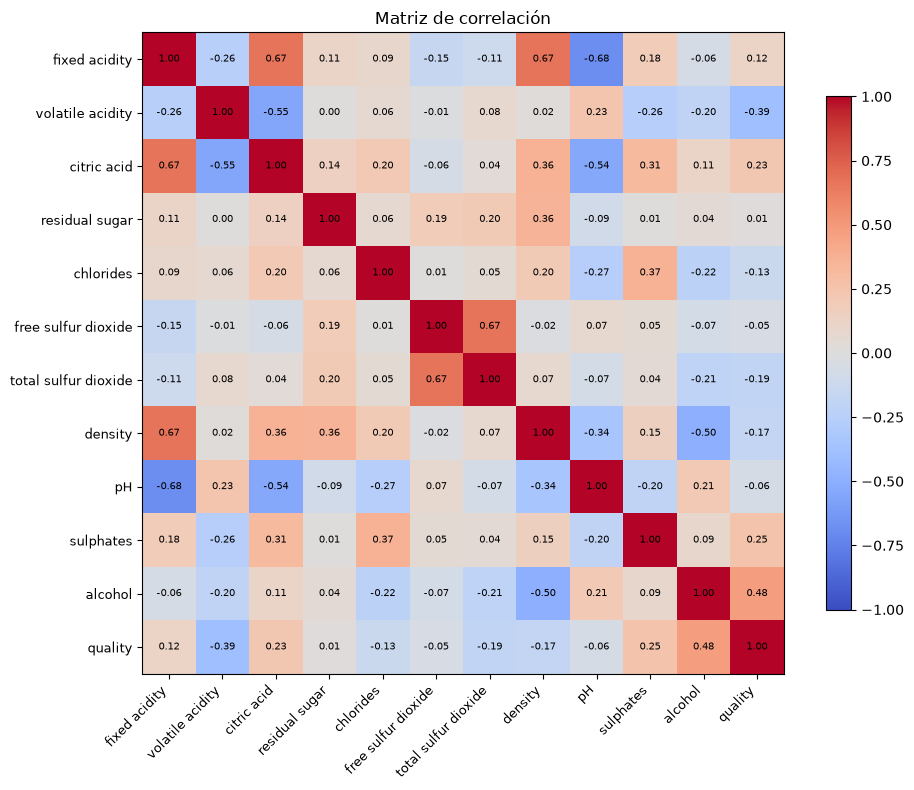

alcohol                 0.476
sulphates               0.251
citric acid             0.226
fixed acidity           0.124
residual sugar          0.014
free sulfur dioxide    -0.051
pH                     -0.058
chlorides              -0.129
density                -0.175
total sulfur dioxide   -0.185
volatile acidity       -0.391


In [8]:
corr = df.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right", fontsize=9)
ax.set_yticks(range(len(corr)), corr.columns, fontsize=9)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Matriz de correlación")
plt.tight_layout()
plt.show()

print(corr["quality"].drop("quality").sort_values(ascending=False).round(3).to_string())

El `alcohol` es la variable con mayor asociación positiva con la calidad (0.48) y la
`volatile acidity` la de mayor asociación negativa (−0.39), lo que es consistente con que el
exceso de ácido acético da sabor avinagrado. Son asociaciones, no efectos causales, y ninguna
es alta por sí sola, así que el modelo necesita combinar varias variables.


## 3. Limpieza de datos


In [9]:
print("Valores faltantes:", int(df.isna().sum().sum()))
print("Tipos presentes:", df.dtypes.astype(str).unique().tolist())
print("Columnas no numéricas:",
      [col for col in df.columns if not pd.api.types.is_numeric_dtype(df[col])] or "ninguna")

Valores faltantes: 0
Tipos presentes: ['float64', 'int64']
Columnas no numéricas: ninguna


In [10]:
duplicados = int(df.duplicated().sum())
print("Duplicados:", duplicados, f"({round(100 * duplicados / len(df), 1)} % del total)")

df_limpio = df.drop_duplicates().reset_index(drop=True)
print("Registros antes:", len(df), "| después:", len(df_limpio))

Duplicados: 240 (15.0 % del total)
Registros antes: 1599 | después: 1359


In [11]:
# Regla de 1.5 veces el rango intercuartílico
resumen = []
for col in variables:
    q1, q3 = df_limpio[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    fuera = ((df_limpio[col] < q1 - 1.5 * iqr) | (df_limpio[col] > q3 + 1.5 * iqr)).sum()
    resumen.append({"variable": col, "extremos": int(fuera),
                    "porcentaje": round(100 * fuera / len(df_limpio), 1)})

pd.DataFrame(resumen).sort_values("extremos", ascending=False).reset_index(drop=True)

,variable,extremos,porcentaje
0,residual sugar,126,9.3
1,chlorides,87,6.4
2,sulphates,55,4.0
3,total sulfur dioxide,45,3.3
4,fixed acidity,41,3.0
5,density,35,2.6
6,pH,28,2.1
7,free sulfur dioxide,26,1.9
8,volatile acidity,19,1.4
9,alcohol,12,0.9


In [12]:
# El corte en 7 convierte la calificación de los catadores en un problema binario
df_limpio["buen_vino"] = (df_limpio["quality"] >= 7).astype(int)

print(df_limpio["buen_vino"].value_counts().rename({0: "no bueno", 1: "bueno"}).to_string())
print("\nVinos buenos:", round(100 * df_limpio["buen_vino"].mean(), 1), "%")

buen_vino
no bueno    1175
bueno        184

Vinos buenos: 13.5 %


### Decisiones de limpieza

1. **Faltantes.** No hay ninguno en las 12 columnas, así que no se imputa nada. Queda la
   verificación como evidencia.
2. **Tipos.** Las 11 mediciones son `float` y `quality` es `int`, que es lo correcto. Sin
   conversiones.
3. **Duplicados.** Se eliminan los 240 registros repetidos, un 15 % del total. Son filas
   idénticas en las 12 columnas, así que darían peso artificial a esos vinos y, peor aún,
   podrían quedar repartidas entre entrenamiento y prueba, inflando la métrica con datos que
   el modelo ya vio.
4. **Valores extremos.** Se decide conservarlos. Están dentro de rangos químicamente
   plausibles y no hay evidencia de errores de captura. Eliminarlos reduciría la muestra y
   quitaría justo los vinos que más se alejan del promedio.
5. **Variable objetivo.** `buen_vino` vale 1 si la calidad es 7 u 8, lo que convierte el
   problema en clasificación binaria. Tras eliminar duplicados quedan 13.5 % de casos
   positivos (13.6 % en los datos originales).

## Secciones 4 a 7

El modelo base, su evaluación y el registro en MLflow se migraron a `main.py` y al paquete
`wine_quality` en la actividad de la semana 4. Este notebook se conserva solo para la
exploración de datos y las decisiones de limpieza que aplica `wine_quality/dataset.py`.

## Referencias

Cortez, P., Cerdeira, A., Almeida, F., Matos, T. y Reis, J. (2009). Modeling wine preferences by
data mining from physicochemical properties. *Decision Support Systems, 47*(4), 547–553.
https://doi.org/10.1016/j.dss.2009.05.016

Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine
Learning Research, 12*, 2825–2830.